# 数据分析流程
采集数据--确定分析方向--导入数据--数据清洗--数据分析--数据可视化
```
#   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   city        106118 non-null  object
 1   address     104452 non-null  object
 2   area        105324 non-null  object
 3   floor       104024 non-null  object
 4   name        105564 non-null  object
 5   price       105564 non-null  object
 6   province    106118 non-null  object
 7   rooms       104036 non-null  object
 8   toward      105240 non-null  object
 9   unit        105564 non-null  object
 10  year        57736 non-null   object
 11  origin_url  105564 non-null  object
dtypes: object(12)
memory usage: 9.7+ MB
```
## 具体步骤
1. 数据导入
2. 数据类型转换
3. 异常值处理
4. 数据特征构造
5. 特征相关性
6. 数据可视化：(房价分布直方图)
7. 具体需求，数据分析

# 分析及统计问题
1. 哪些变量最影响房价？面积、楼层、房间数哪个影响更大？特征相关性；了解房屋各特征对房价的影响。
2. 全国房价总体分布是怎样的？是否存在极端值？描述性统计该数字的分布。
3. 哪些城市房价最高直辖市与非直辖市差异如何？城市对比；比较不同城市房价水平。
4. 高价房在面积、楼层等方面有什么特征？价格分层；不同价位房屋特征。
5. 哪种户型最受欢迎？三室比两室贵多少？户型分析；分析不同户型的市场。
6. 南北向是否比单一朝向贵？贵多少贵多少？朝向溢价。；评估不同朝向的价格。
7. 新房比10年老房贵多少？折旧规律如何？？楼龄效应；研究建筑年份对房价的影响。

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['STHeiti']


In [2]:
df = pd.read_csv('data/house_sales.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106118 entries, 0 to 106117
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   city        106118 non-null  object
 1   address     104452 non-null  object
 2   area        105324 non-null  object
 3   floor       104024 non-null  object
 4   name        105564 non-null  object
 5   price       105564 non-null  object
 6   province    106118 non-null  object
 7   rooms       104036 non-null  object
 8   toward      105240 non-null  object
 9   unit        105564 non-null  object
 10  year        57736 non-null   object
 11  origin_url  105564 non-null  object
dtypes: object(12)
memory usage: 9.7+ MB


In [3]:
# 数据总览
print('总记录数：', len(df))
print('字段数量：', len(df.columns))
df.head()

总记录数： 106118
字段数量： 12


,city,address,area,floor,name,price,province,rooms,toward,unit,year,origin_url
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
1,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
2,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
3,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37㎡,中层（共22层）,文一名门金隅,32万,安徽,2室1厅,南北向,8649元/㎡,2017年建,https://hf.esf.fang.com/chushou/3_404372096.htm


In [4]:
# 数据清洗
# 删除无用的数据列
df.drop(columns='origin_url', inplace=True)     # 原地删除


In [5]:
# 检查是否有缺失值
df.isna().sum()
# 删除缺失值
df.dropna(inplace=True)

In [6]:
# 检查是否有重复值
df.duplicated().sum()
# 删除重复数据
df.drop_duplicates(inplace=True)
print(len(df))

28104


In [7]:
# 面积数据类型转换
df['area'] = df['area'].str.replace('㎡', '').astype(float)

In [8]:
# 售价的数据类型转换
df['price'] = df['price'].str.replace('万','').astype(float)

In [9]:
# 朝向的数据类型转换
df['toward'] = df['toward'].astype('category')

In [10]:
# province 类别处理
df['province'] = df['province'].astype('category')
len(df['province'].unique())

28

In [11]:
# unit数据类型转换
df['unit'] = df['unit'].str.replace('元/㎡', '').astype(float)

In [12]:
# year的数据类型转换
df['year'] = df['year'].str.replace('年建', '').astype(int)

In [13]:
# 异常值处理
# 房屋面积的异常处理
len(df[(df['area'] < 20) & (df['area'] > 600)])
df = df[(df['area'] > 20) & (df['area'] < 600)]

In [14]:
# 房屋售价的异常处理 IQR【不太适合IQR处理】
# Q1 = df['price'].quantile(0.25)
# Q3 = df['price'].quantile(0.75)
# IQR = Q3 - Q1
# low_price = Q1 - 1.5 * IQR
# high_price = Q3 + 1.5 * IQR
# len(df[df['price'] > high_price])   # 1944


## 新数据特征构造
1. 地区district
2. 楼层的类型floor_type
3. 是否是直辖市zxs
4. 卧室的数量 bedrooms
5. 客厅的数量 livingrooms
6. 楼龄 building_age
7. 价格的分度 price_labels


In [19]:
# district
df['district'] = df['address'].str.split('-').str[0]
# df['address'] = df['address'].str.split('-')

In [29]:
# floor_type
df.sample(10)       # 随机取样
# df['floor_type'] = df['floor'].str.split('（').str[0].astype('category')        # 同上的方法
# 使用函数的方法
def fun1(str1):
    if pd.isna(str1):
        return '未知'
    elif '低' in str1:
        return '低楼层'
    elif '中' in str1:
        return '中楼层'
    elif '高' in str1:
        return '高楼层'
df['floor_type2'] = df['floor'].apply(fun1).astype('category')

In [34]:
# 是否是直辖市 [lambda形式]
df['zxs'] = df['city'].apply(lambda x: 1 if x in ['北京', '上海', '天津', '重庆'] else 0)

In [43]:
# 卧室的数量bedrooms
df['bedrooms'] = df['rooms'].str.split('室').str[0].astype(int)

In [50]:
# 客厅的数量livingrooms
# df['rooms'].str.split('室').str[1].str.split('厅').str[0].astype(int)
df['livingrooms'] = df['rooms'].str.extract(r'(\d+)厅').astype(int)

In [52]:
# 楼龄building_age
df['building_age'] = 2026 - df['year']

In [54]:
# 价格的分段price_labels,【直接进行分箱操作】
df['price_labels'] = pd.cut(df['price'], bins=4, labels=['低价',  '中价', '高价', '豪华'])

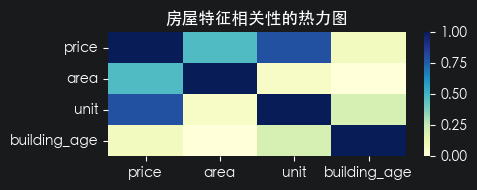

In [66]:
'''
A1: 哪些变量最影响房价？面积、楼层、房间数哪个影响更大？
分析主题：特征相关性
分析目标：了解房屋各个特征对房价的线性影响
分组字段：无
指标/方法：皮尔逊相关系数
'''

a = df[['price', 'area', 'unit', 'building_age']].corr()        # 相关系数
"""
根据相关系数可以看到，正相关和负相关。
价格和单位价格的相关性明显
面积和楼龄呈现负相关性
"""
a['price'].sort_values(ascending=False) [1:]    # 切掉price本身
# 相关性的热力图
plt.figure(figsize=(5, 2))
sns.heatmap(a, cmap='YlGnBu', vmin=0, vmax=1)
plt.title('房屋特征相关性的热力图')
plt.tight_layout()

In [67]:
"""
A2: 全国房价总体分布是怎样的？是否存在极端值？
分析主题：描述性统计
分析目标：概览数值性字段的分布特征
分组字段：无
指标/方法：平均值、中位数、四分位数、标准差
"""
df.describe()


,area,price,unit,year,zxs,bedrooms,livingrooms,building_age
count,28079.000000,28079.000000,28079.000000,28079.000000,28079.000000,28079.000000,28079.000000,28079.000000
mean,107.829038,147.541519,13429.487553,2012.924463,0.011895,2.770398,1.857687,13.075537
std,41.189153,173.377815,10920.563531,6.117544,0.108416,0.845008,0.411881,6.117544
min,21.000000,9.000000,1000.000000,1930.000000,0.000000,0.000000,0.000000,3.000000
25%,86.000000,74.000000,7779.500000,2010.000000,0.000000,2.000000,2.000000,9.000000
50%,101.400000,109.000000,10833.000000,2015.000000,0.000000,3.000000,2.000000,11.000000
75%,126.000000,167.000000,15396.000000,2017.000000,0.000000,3.000000,2.000000,16.000000
max,588.000000,6899.000000,456311.000000,2023.000000,1.000000,9.000000,12.000000,96.000000


In [74]:
df = df[df['price'] < 20000]


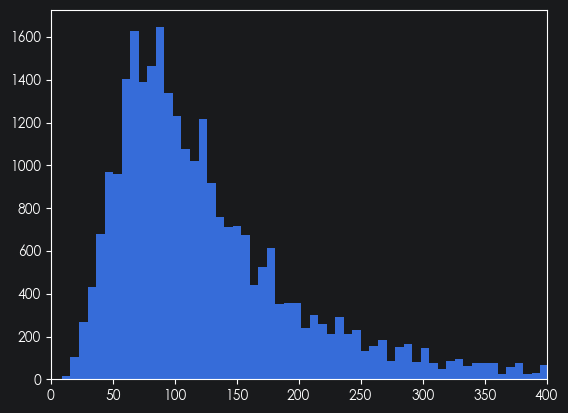

In [91]:
# 房价的分布直方图
plt.subplot(111)
plt.hist(df['price'], bins=1000)
plt.xlim(0, 400)
plt.show()

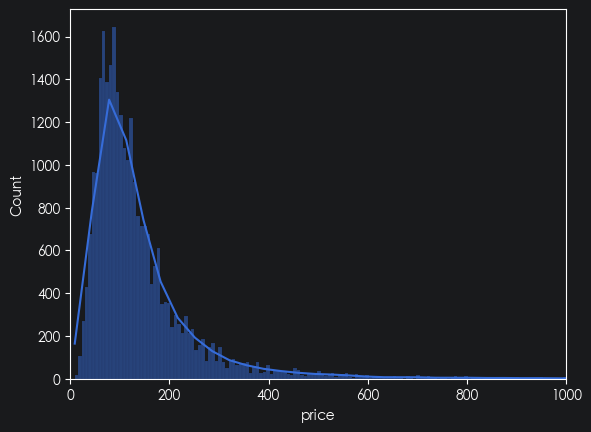

In [94]:
sns.histplot(data=df, x='price', bins=1000, kde=True)
plt.xlim(0, 1000)
plt.show()

In [99]:
"""
A6：南北向是否真比单一朝向贵？贵多少？
分析主题：朝向溢价
分析目标：评估不同朝向的价格差异
分组字段：toward
指标/方法：方差分析、多重比较
"""

df['toward'].value_counts().sort_values(ascending=False)
df.groupby('toward').agg({
    'price': ['mean', 'median'],
    'unit': ['median'],
    'building_age': ['mean'],
})

/var/folders/b4/qwh98z_d37gg2_qygwhw2x900000gn/T/ipykernel_3706/1183313652.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('toward').agg({


price             unit building_age
              mean  median   median         mean
toward                                          
东北向     185.842480  109.88  12993.0    14.432000
东南向     177.744554  116.00  11950.0    12.531053
东向      136.787982  100.00  11786.0    13.838565
东西向     124.032099   86.40   9432.0    16.425926
北向      120.377536   80.90  12000.0    14.271739
南北向     148.572904  110.00  10358.0    13.219064
南向      140.854862  108.00  11250.0    12.628419
西北向     146.045725  108.00  12555.0    14.471014
西南向     223.074026  156.00  15052.0    15.220779
西向      153.508956   95.90  13431.0    14.626374

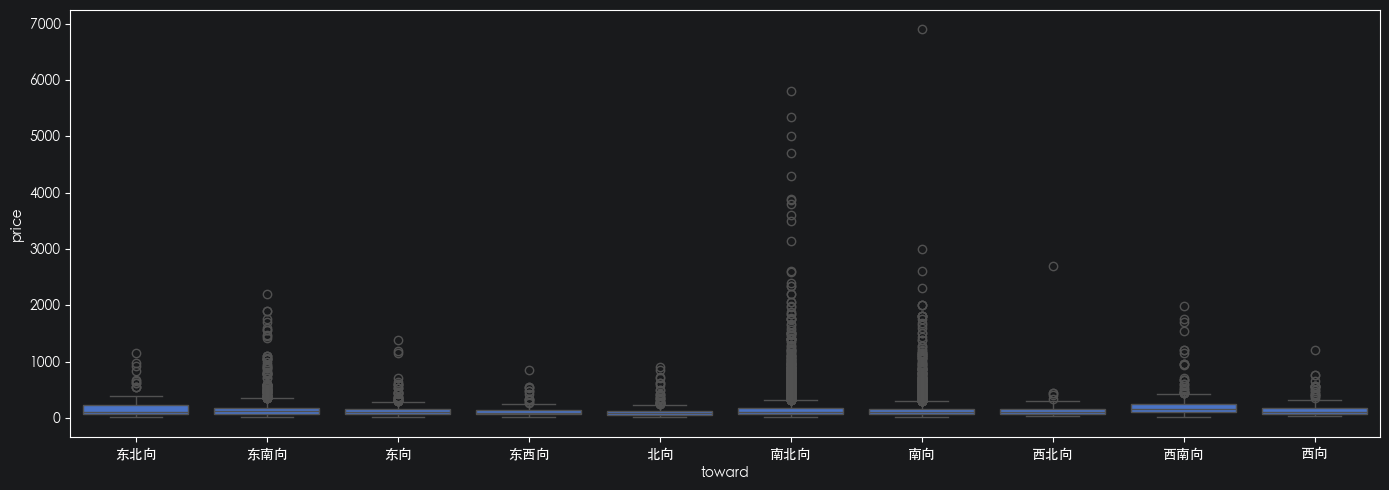

In [100]:
# 数据可视化
plt.figure(figsize=(14, 5))
sns.boxplot(x='toward', y='price', data=df)
plt.tight_layout()

 # 新增方法内容
1. IQR异常处理方法
2. sample() 随机取样
3. apply(func1)。可以直接导入函数
4. extract()
5. corr() 相关系数
6. sns.heatmap()  热力图
7. describe() 描述文件
8. groupby()  分组
9. agg() 聚合

In [78]:
df.head()

,city,address,area,floor,name,price,province,rooms,toward,unit,year,district,floor_type,floor_type2,zxs,bedrooms,livingrooms,building_age,price_labels
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90.0,中层（共18层）,圣地亚哥,128.0,安徽,3室2厅,南北向,14222.0,2013,龙岗,中层,中楼层,0,3,2,13,低价
2,合肥,生态公园-淮海大道与大众路交口,95.0,中层（共18层）,正荣·悦都荟,132.0,安徽,3室2厅,南向,13895.0,2019,生态公园,中层,中楼层,0,3,2,7,低价
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37.0,中层（共22层）,文一名门金隅,32.0,安徽,2室1厅,南北向,8649.0,2017,撮镇,中层,中楼层,0,2,1,9,低价
6,合肥,龙岗-长江东路与和县里交口,50.0,高层（共30层）,柏庄金座,46.0,安徽,2室1厅,南向,9200.0,2019,龙岗,高层,高楼层,0,2,1,7,低价
8,合肥,新亚汽车站-张洼路与临泉路交汇处向北100米(原红星机械,120.0,中层（共27层）,天目未来,158.0,安徽,4室2厅,南向,13167.0,2012,新亚汽车站,中层,中楼层,0,4,2,14,低价
